# Wald vs. Wilson 95% intervals for an accuracy

Why the paper quotes **Wilson** intervals for the accuracies in Fig. 2 rather
than the textbook "measured value ± 1.96 standard errors" (**Wald**).

With $\hat p$ the measured accuracy (k correct of n) and $z = 1.96$:

* **Wald:** $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ -- the spread is estimated
  from the measured value itself.
* **Wilson:** every true accuracy $p$ for which the measurement lies within
  $z$ standard errors *computed at that $p$*,
  $|\hat p - p| \le z\sqrt{p(1-p)/n}$. Solving for $p$ gives
  $\dfrac{\hat p + z^2/2n \pm z\sqrt{\hat p(1-\hat p)/n + z^2/4n^2}}{1 + z^2/n}$.

**The figure.** A confidence interval is not itself a probability
distribution, but each method implies a curve over candidate true accuracies,
peak-normalised to 1: a candidate is inside the 95% interval wherever its curve
stays above the dotted line at $e^{-z^2/2} \approx 0.15$. The exact binomial
likelihood (grey, dotted) is the reference both approximate.

Edit `example_cells` to look at other accuracies; `n = 85` per category, `170`
for the pooled sky-image column of Fig. 2.

In [1]:
# ======================== CONFIG ========================
# (panel title, number correct, number of figures)
example_cells = [
    ('Worst case: 50% of 85',                  42.5, 85),
    ('Gemini, contours: 69 of 85 (81%)',        69,   85),
    ('Gemini, GMM-sky aged: 3 of 85 (4%)',      3,    85),
    ('Gemini, sky images: 170 of 170 (100%)',   170,  170),
]

save_to = None    # e.g. '~/Dropbox/WASP2026/ref_report/wald_vs_wilson.png'; None = show only

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Z = 1.959964                      # two-sided 95%
CUT = np.exp(-Z**2 / 2)           # inside the interval where a curve is >= this


def wald_interval(k, n, z=Z):
    """Measured value +/- z standard errors, the SE estimated at the measured value."""
    ph = k / n
    h = z * np.sqrt(ph * (1 - ph) / n)
    return ph - h, ph + h


def wilson_interval(k, n, z=Z):
    """Every true p for which the measurement is within z SEs computed at p."""
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h


table = pd.DataFrame([{'cell': t, 'k': k, 'n': n, 'measured %': 100 * k / n,
                       'Wald low': 100 * wald_interval(k, n)[0], 'Wald high': 100 * wald_interval(k, n)[1],
                       'Wilson low': 100 * wilson_interval(k, n)[0], 'Wilson high': 100 * wilson_interval(k, n)[1]}
                      for t, k, n in example_cells]).set_index('cell')
table.round(1)

,k,n,measured %,Wald low,Wald high,Wilson low,Wilson high
cell,,,,,,,
Worst case: 50% of 85,42.5,85,50.0,39.4,60.6,39.6,60.4
"Gemini, contours: 69 of 85 (81%)",69.0,85,81.2,72.9,89.5,71.6,88.1
"Gemini, GMM-sky aged: 3 of 85 (4%)",3.0,85,3.5,-0.4,7.5,1.2,9.9
"Gemini, sky images: 170 of 170 (100%)",170.0,170,100.0,100.0,100.0,97.8,100.0


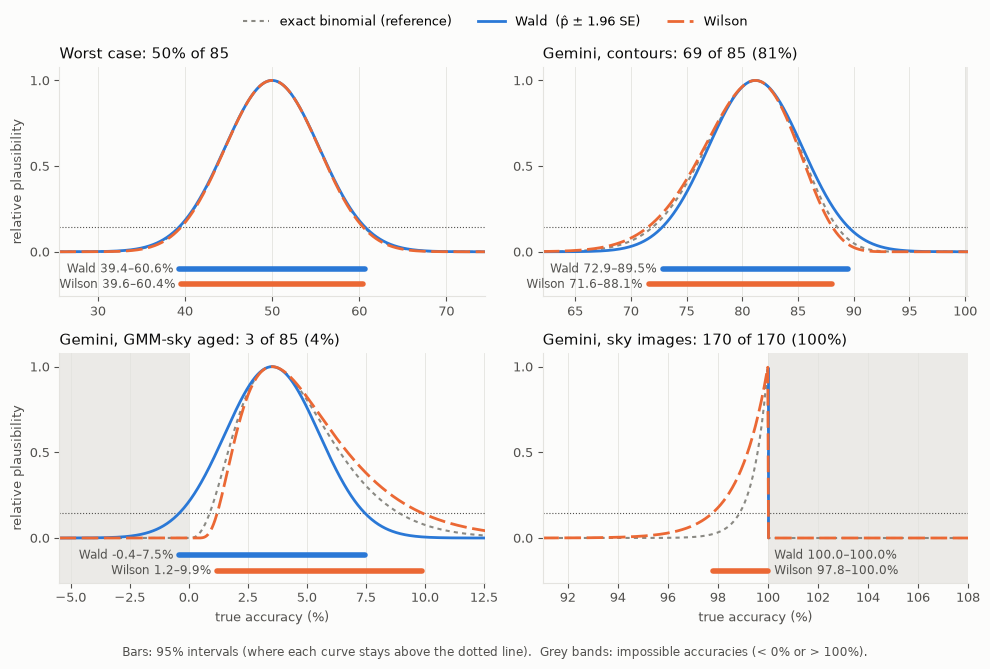

In [3]:
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
WALD, WILSON, EXACT = '#2a78d6', '#eb6834', '#8a8983'

p = np.linspace(-0.08, 1.08, 4001)          # candidate true accuracies, a little past 0 and 1
inside = (p > 0) & (p < 1)
x = 100 * p

nrow = int(np.ceil(len(example_cells) / 2))
fig, axes = plt.subplots(nrow, 2, figsize=(10, 3.3 * nrow), facecolor=SURF, squeeze=False)
for ax in axes.flat[len(example_cells):]:
    ax.set_visible(False)

for ax, (title, k, n) in zip(axes.flat, example_cells):
    ph = k / n
    se = np.sqrt(ph * (1 - ph) / n)

    # Wald: a normal curve centred on the measured value, width from the measured value
    if se > 0:
        wald = np.exp(-0.5 * ((p - ph) / se) ** 2)
    else:
        wald = np.where(np.isclose(p, ph, atol=2e-4), 1.0, 0.0)     # zero width
    # Wilson: for each candidate true p, how far the measurement sits in SEs computed AT p
    wil = np.zeros_like(p)
    zs = (ph - p[inside]) / np.sqrt(p[inside] * (1 - p[inside]) / n)
    wil[inside] = np.exp(-0.5 * zs ** 2)
    # exact binomial likelihood, peak-normalised: the reference both approximate
    lik = np.zeros_like(p)
    with np.errstate(divide='ignore', invalid='ignore'):
        ll = k * np.log(p[inside]) + (n - k) * np.log1p(-p[inside])
    lik[inside] = np.exp(ll - np.nanmax(ll))

    ax.set_facecolor(SURF)
    ax.axvspan(-8, 0, color=GRID, alpha=0.7, lw=0)            # impossible accuracies
    ax.axvspan(100, 108, color=GRID, alpha=0.7, lw=0)
    ax.axhline(CUT, color=INK2, lw=0.8, ls=':')
    ax.plot(x, lik, color=EXACT, lw=1.5, ls=(0, (2, 2)), label='exact binomial (reference)')
    if se > 0:
        ax.plot(x, wald, color=WALD, lw=2, label='Wald  (p̂ ± 1.96 SE)')
    else:
        ax.vlines(100 * ph, 0, 1, color=WALD, lw=2, label='Wald  (p̂ ± 1.96 SE)')
    ax.plot(x, wil, color=WILSON, lw=2, ls=(0, (6, 2)), label='Wilson')

    # zoom on the action: centre each panel on its interval
    lo_view = max(-8, 100 * (ph - 4.5 * max(se, 0.02)))
    hi_view = min(108, 100 * (ph + 4.5 * max(se, 0.02)))
    span = hi_view - lo_view

    # the two intervals as bars under the curves, from the closed-form formulas
    for y, (lo, hi), col, name in ((-0.10, wald_interval(k, n), WALD, 'Wald'),
                                   (-0.19, wilson_interval(k, n), WILSON, 'Wilson')):
        lo, hi = 100 * lo, 100 * hi
        ax.plot([lo, hi], [y, y], color=col, lw=4, solid_capstyle='round')
        right_room = hi_view - hi > 0.32 * span          # room for the label right of the bar?
        ax.text(hi + 0.015 * span if right_room else lo - 0.015 * span, y,
                '%s %.1f–%.1f%%' % (name, lo, hi), va='center',
                ha='left' if right_room else 'right', fontsize=8.5, color=INK2)

    ax.set_title(title, fontsize=10.5, color=INK, loc='left')
    ax.set_ylim(-0.26, 1.08)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlim(lo_view, hi_view)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis='x', color=GRID, lw=0.6)
    ax.set_axisbelow(True)

for ax in axes[-1]:
    ax.set_xlabel('true accuracy (%)', color=INK2, fontsize=9.5)
for ax in axes[:, 0]:
    ax.set_ylabel('relative plausibility', color=INK2, fontsize=9.5)

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.995))
fig.text(0.5, 0.005, 'Bars: 95% intervals (where each curve stays above the dotted line).  '
         'Grey bands: impossible accuracies (< 0% or > 100%).',
         ha='center', fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
if save_to:
    fig.savefig(os.path.expanduser(save_to), dpi=150, facecolor=SURF)
    print('wrote', save_to)
plt.show()